# EDA — Give Me Some Credit Dataset

150k loan applicants, ~6.7% defaulted within 2 years.
Goal: understand the data before touching it — missing values, distributions, outliers, class imbalance.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', palette='muted')
%matplotlib inline

In [2]:
df = pd.read_csv('../data/raw/cs-training.csv', index_col=0)  # index_col=0 drops the unnamed row-index column
print('Shape:', df.shape)
df.head()

Shape: (150000, 11)


,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


## Column overview

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150000 entries, 1 to 150000
Data columns (total 11 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   SeriousDlqin2yrs                      150000 non-null  int64  
 1   RevolvingUtilizationOfUnsecuredLines  150000 non-null  float64
 2   age                                   150000 non-null  int64  
 3   NumberOfTime30-59DaysPastDueNotWorse  150000 non-null  int64  
 4   DebtRatio                             150000 non-null  float64
 5   MonthlyIncome                         120269 non-null  float64
 6   NumberOfOpenCreditLinesAndLoans       150000 non-null  int64  
 7   NumberOfTimes90DaysLate               150000 non-null  int64  
 8   NumberRealEstateLoansOrLines          150000 non-null  int64  
 9   NumberOfTime60-89DaysPastDueNotWorse  150000 non-null  int64  
 10  NumberOfDependents                    146076 non-null  float64
dtypes: float64(

In [4]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
SeriousDlqin2yrs,150000.0,0.07,0.25,0.0,0.00,0.00,0.00,1.0
RevolvingUtilizationOfUnsecuredLines,150000.0,6.05,249.76,0.0,0.03,0.15,0.56,50708.0
age,150000.0,52.30,14.77,0.0,41.00,52.00,63.00,109.0
NumberOfTime30-59DaysPastDueNotWorse,150000.0,0.42,4.19,0.0,0.00,0.00,0.00,98.0
DebtRatio,150000.0,353.01,2037.82,0.0,0.18,0.37,0.87,329664.0
MonthlyIncome,120269.0,6670.22,14384.67,0.0,3400.00,5400.00,8249.00,3008750.0
NumberOfOpenCreditLinesAndLoans,150000.0,8.45,5.15,0.0,5.00,8.00,11.00,58.0
NumberOfTimes90DaysLate,150000.0,0.27,4.17,0.0,0.00,0.00,0.00,98.0
NumberRealEstateLoansOrLines,150000.0,1.02,1.13,0.0,0.00,1.00,2.00,54.0
NumberOfTime60-89DaysPastDueNotWorse,150000.0,0.24,4.16,0.0,0.00,0.00,0.00,98.0


## Target distribution

Classic class imbalance — only ~6.7% defaulted. This means accuracy is a useless metric here.

                   count    pct
SeriousDlqin2yrs               
0                 139974  0.933
1                  10026  0.067


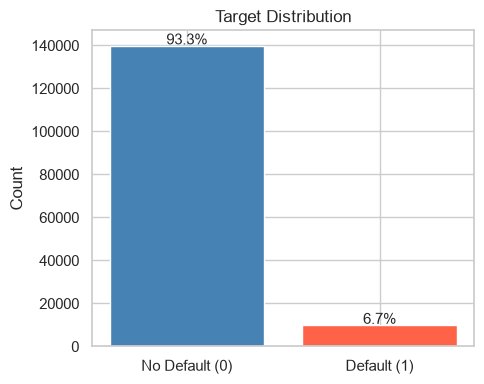

In [5]:
target = 'SeriousDlqin2yrs'

counts = df[target].value_counts()
pcts   = df[target].value_counts(normalize=True).round(3)

print(pd.DataFrame({'count': counts, 'pct': pcts}))

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(['No Default (0)', 'Default (1)'], counts.values, color=['steelblue', 'tomato'], edgecolor='white')
ax.set_title('Target Distribution')
ax.set_ylabel('Count')
for i, v in enumerate(counts.values):
    ax.text(i, v + 500, f'{pcts.values[i]*100:.1f}%', ha='center', fontsize=11)
plt.tight_layout()
plt.savefig('../reports/figures/target_distribution.png', dpi=150)
plt.show()

## Missing values

In [6]:
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)

miss_df = pd.DataFrame({'missing_count': missing, 'missing_pct': missing_pct})
miss_df[miss_df.missing_count > 0].sort_values('missing_pct', ascending=False)

,missing_count,missing_pct
MonthlyIncome,29731,19.82
NumberOfDependents,3924,2.62


**Expected findings:**
- `MonthlyIncome` — ~19.8% missing (significant, can't just drop)
- `NumberOfDependents` — ~2.6% missing (small, median fill is fine)

We'll handle these in the feature engineering notebook.

## Outlier check

Some columns in this dataset have wild extreme values — worth checking before modeling.

In [7]:
# RevolvingUtilizationOfUnsecuredLines should be 0–1 (it's a ratio)
# but some values are in the hundreds/thousands
print('RevolvingUtilization max:', df['RevolvingUtilizationOfUnsecuredLines'].max())
print('RevolvingUtilization > 1 count:', (df['RevolvingUtilizationOfUnsecuredLines'] > 1).sum())

print()

# age — should have no zeros
print('Age min:', df['age'].min())
print('Age == 0 count:', (df['age'] == 0).sum())

print()

# past-due columns — 96 and 98 are often sentinel values in this dataset
past_due_cols = [
    'NumberOfTime30-59DaysPastDueNotWorse',
    'NumberOfTime60-89DaysPastDueNotWorse',
    'NumberOfTimes90DaysLate'
]
for col in past_due_cols:
    print(f'{col} — max: {df[col].max()}, values > 10: {(df[col] > 10).sum()}')

RevolvingUtilization max: 50708.0
RevolvingUtilization > 1 count: 3321

Age min: 0
Age == 0 count: 1

NumberOfTime30-59DaysPastDueNotWorse — max: 98, values > 10: 273
NumberOfTime60-89DaysPastDueNotWorse — max: 98, values > 10: 270
NumberOfTimes90DaysLate — max: 98, values > 10: 285


## Feature distributions

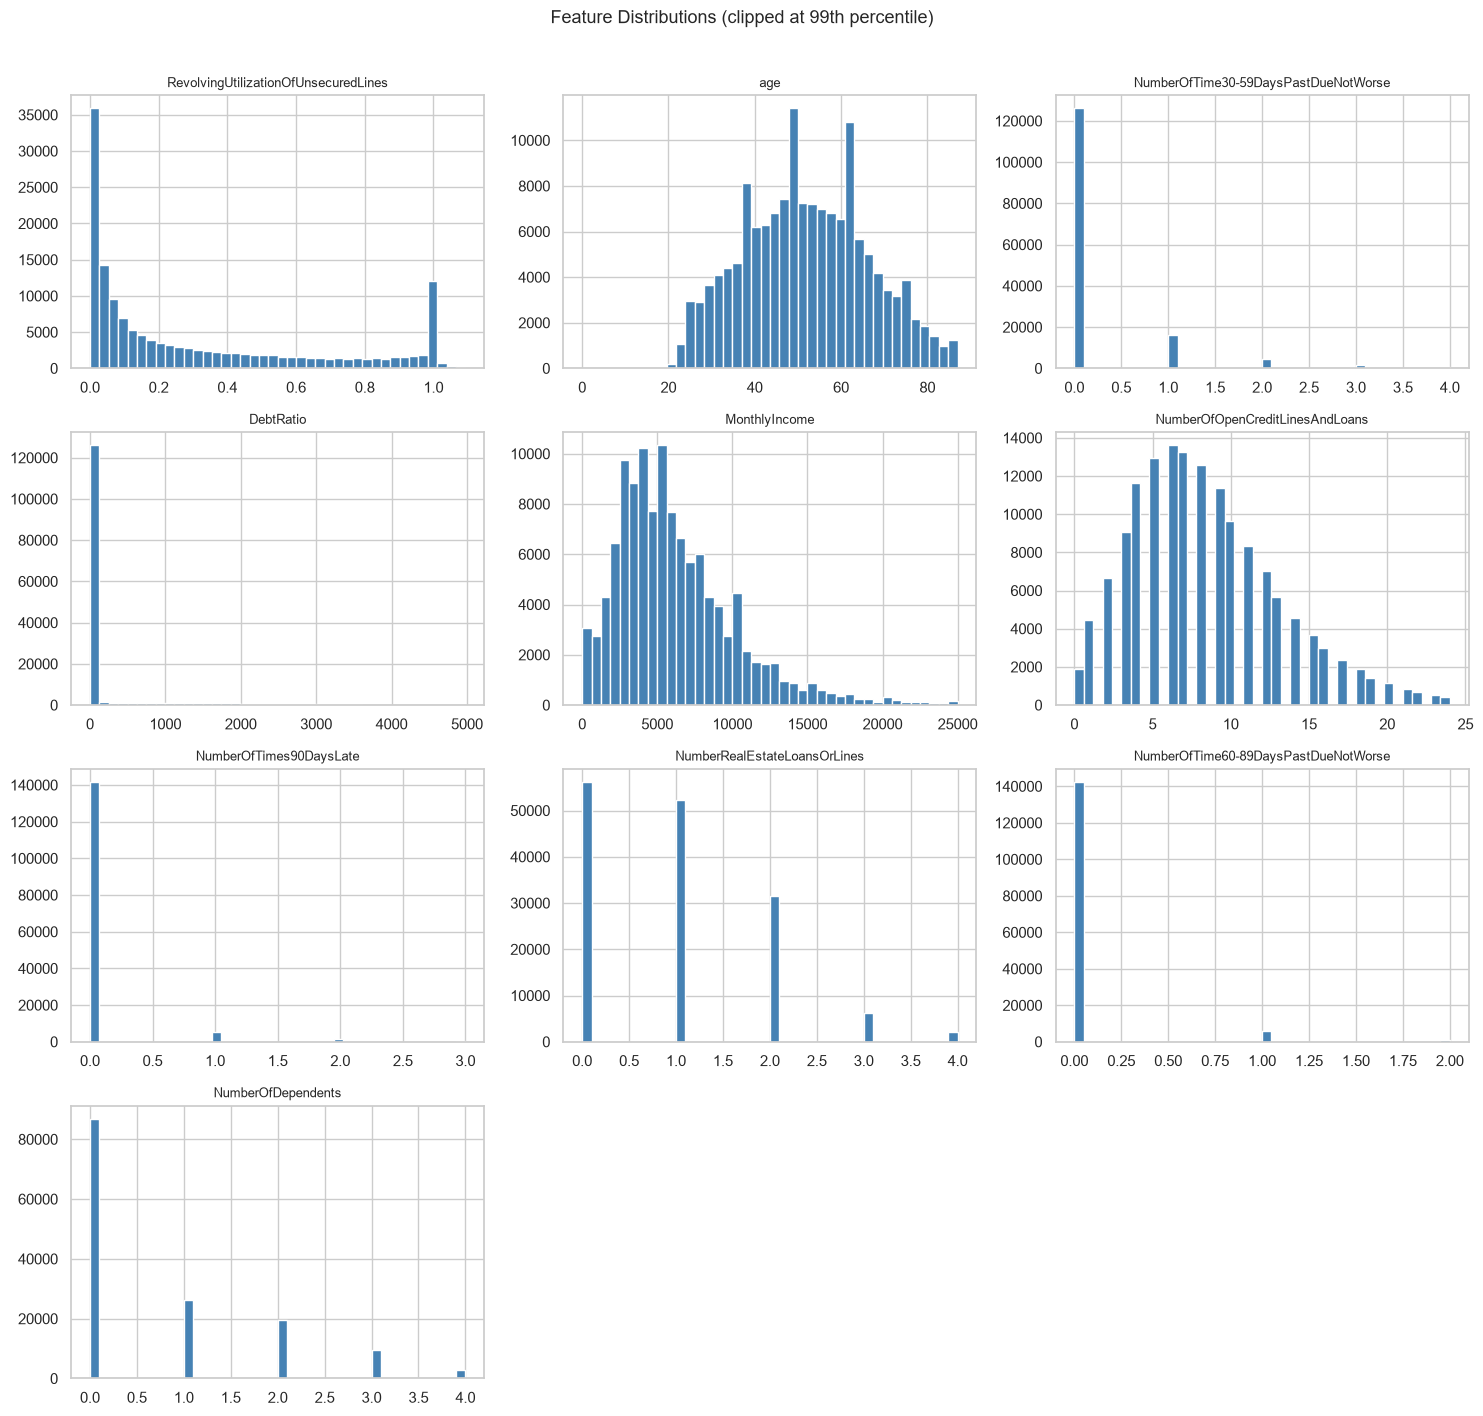

In [8]:
feature_cols = [c for c in df.columns if c != target]

fig, axes = plt.subplots(nrows=4, ncols=3, figsize=(15, 14))
axes = axes.flatten()

for i, col in enumerate(feature_cols):
    data = df[col].dropna()
    # clip extreme outliers just for visualization
    p99 = data.quantile(0.99)
    data = data[data <= p99]
    axes[i].hist(data, bins=40, color='steelblue', edgecolor='white')
    axes[i].set_title(col, fontsize=9)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Feature Distributions (clipped at 99th percentile)', fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig('../reports/figures/feature_distributions.png', dpi=150)
plt.show()

## Default rate by feature

How does default rate change across different feature ranges?

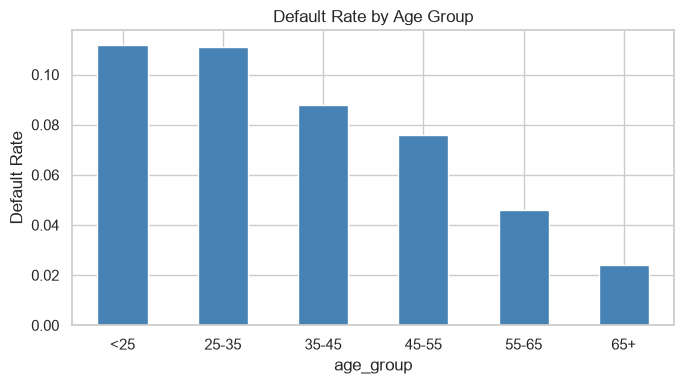

age_group
<25      0.112
25-35    0.111
35-45    0.088
45-55    0.076
55-65    0.046
65+      0.024
Name: SeriousDlqin2yrs, dtype: float64


In [9]:
# default rate by age group
df['age_group'] = pd.cut(df['age'], bins=[0, 25, 35, 45, 55, 65, 120], labels=['<25', '25-35', '35-45', '45-55', '55-65', '65+'])
age_default = df.groupby('age_group', observed=True)[target].mean().round(3)

age_default.plot(kind='bar', color='steelblue', edgecolor='white', figsize=(7, 4))
plt.title('Default Rate by Age Group')
plt.ylabel('Default Rate')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('../reports/figures/default_rate_by_age.png', dpi=150)
plt.show()

print(age_default)

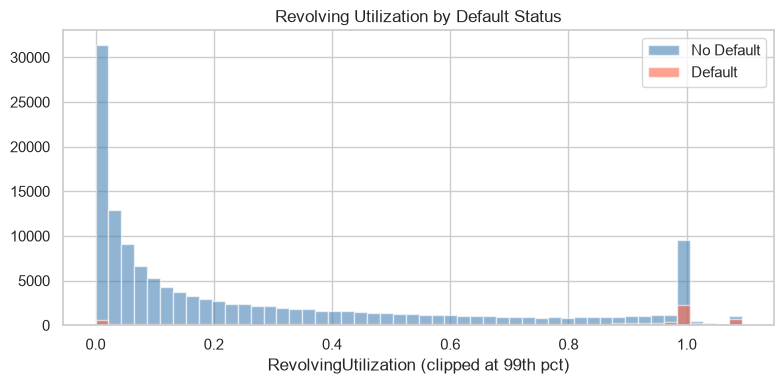

In [10]:
# how does revolving utilization differ between defaulters and non-defaulters?
clip_val = df['RevolvingUtilizationOfUnsecuredLines'].quantile(0.99)

fig, ax = plt.subplots(figsize=(8, 4))
for label, color in [(0, 'steelblue'), (1, 'tomato')]:
    data = df[df[target] == label]['RevolvingUtilizationOfUnsecuredLines'].clip(upper=clip_val)
    ax.hist(data, bins=50, alpha=0.6, label=f'{"No Default" if label == 0 else "Default"}', color=color, edgecolor='white')

ax.set_title('Revolving Utilization by Default Status')
ax.set_xlabel('RevolvingUtilization (clipped at 99th pct)')
ax.legend()
plt.tight_layout()
plt.savefig('../reports/figures/utilization_by_default.png', dpi=150)
plt.show()

## Correlation heatmap

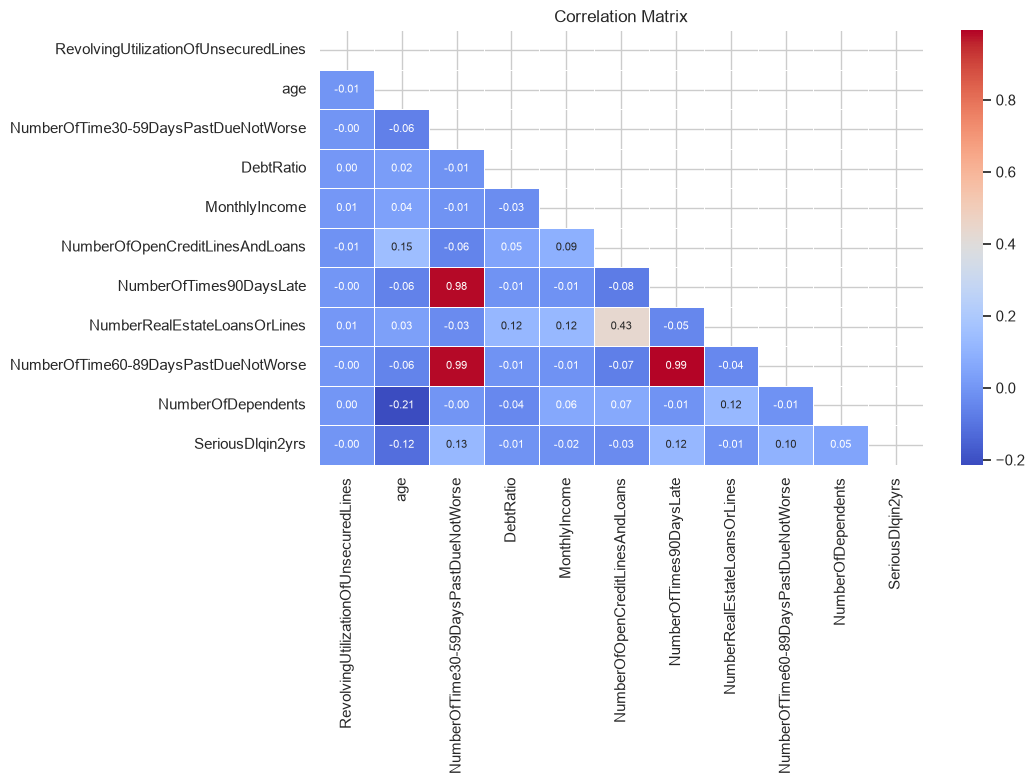

In [11]:
corr_df = df[feature_cols + [target]].drop(columns=['age_group'], errors='ignore')

plt.figure(figsize=(11, 8))
corr = corr_df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5, annot_kws={'size': 8})
plt.title('Correlation Matrix')
plt.tight_layout()
plt.savefig('../reports/figures/correlation_heatmap.png', dpi=150)
plt.show()

## Key takeaways

- **Missing data:** `MonthlyIncome` — 29,731 nulls (19.82%), too many to drop; will use age-group median. `NumberOfDependents` — 3,924 nulls (2.62%), simple median fill is fine
- **Outliers:** `RevolvingUtilization` max is 50,708 — it's a ratio so anything > 1 is wrong (3,321 such rows); will cap at 1.0. One row with `age == 0`, just drop it
- **Sentinel values:** past-due columns have max of 98 — values of 96/98 are error codes, not real counts (273–285 affected rows); will replace with NaN then fill 0
- **Class imbalance:** 93.3% no default / 6.7% default — accuracy is a useless metric here; will use AUC-ROC and precision-recall curve
- **Strongest signals (from distributions):** `RevolvingUtilization`, the three past-due columns, and `DebtRatio` look most correlated with default
- **Next step:** feature engineering — clean the above issues, create new features (total past due, monthly debt estimate, income per dependent)